In [ ]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
print(f"X_train Shape : {X_train.shape}")
print(f"y_train Shape : {y_train.shape}")

print(f"X_test Shape : {X_test.shape}")
print(f"y_test Shape : {y_test.shape}")

X_train Shape : (60000, 28, 28)
y_train Shape : (60000,)
X_test Shape : (10000, 28, 28)
y_test Shape : (10000,)


4


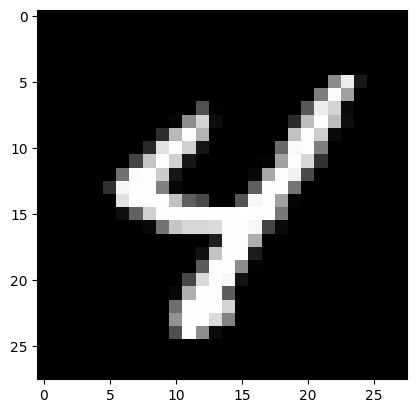

In [ ]:
plt.imshow(X_train[57389], cmap='gray')
print(y_train[57389])

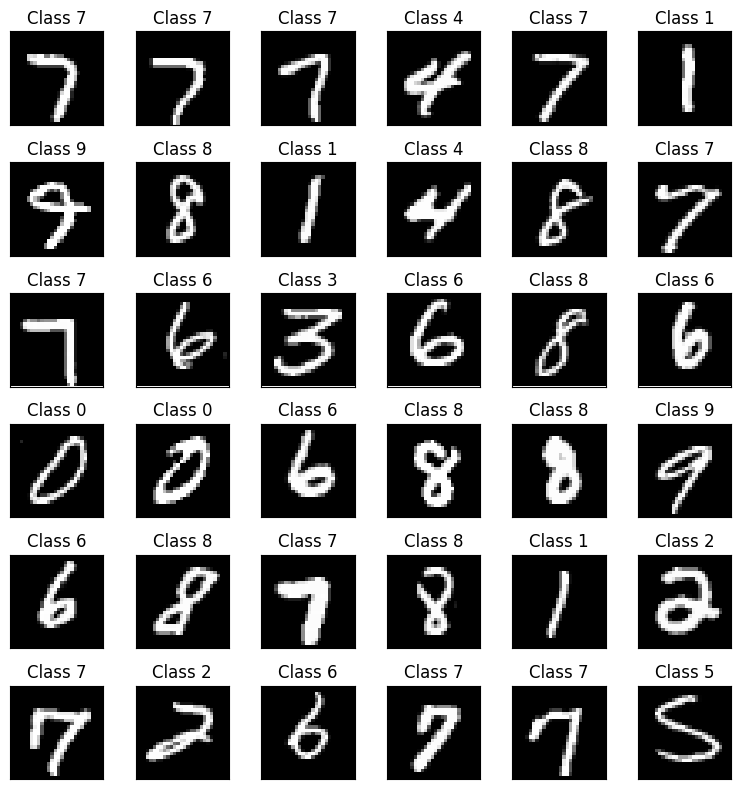

In [ ]:
plt.figure(figsize=(8, 8))
n = 6
for i in range(n * n):
    plt.subplot(n, n, i+1)
    random_idx = np.random.randint(0, X_train.shape[0])
    plt.imshow(X_train[random_idx], cmap='gray')
    plt.title(f'Class {y_train[random_idx]}')
    plt.xticks([])
    plt.yticks([])
    plt.tight_layout()

In [ ]:
print(X_train[57389])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0 140 236  25   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0 125 252 161   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0  80   2   0   0   0   0
    0   0  89 236 211  10   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   6 141 212  13   0   

In [ ]:
X_train_normalized = X_train / 255
X_test_normalized = X_test / 255

In [ ]:
print(X_train_normalized[57389])

[[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.    

In [ ]:
Y_train = tf.keras.utils.to_categorical(y_train, 10)
Y_test = tf.keras.utils.to_categorical(y_test, 10)

In [ ]:
print(y_train[57389])
print(Y_train[57389])

4
[0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]


In [ ]:
from tensorflow.keras.layers import Flatten

In [ ]:
model = Sequential([
    Flatten(input_shape=(28, 28)),
    # Dense Layer, Decide the Number of Neurons to add, activation='relu'
    # Dense Layer, Decide the Number of Neurons to add, activation='relu'
    # Output Dense Layer, 10 neurons, activation='softmax'
    Dense(16, activation='relu'),
    Dense(32, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │        12,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,434 (52.48 KB)

 Trainable params: 13,434 (52.48 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics = ['accuracy']
)

In [ ]:
train_history = model.fit(X_train_normalized, Y_train, batch_size=64, epochs=5)

Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.7322 - loss: 0.8468
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9255 - loss: 0.2592
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9420 - loss: 0.2010
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9478 - loss: 0.1763
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9523 - loss: 0.1617


Text(0, 0.5, 'Loss')

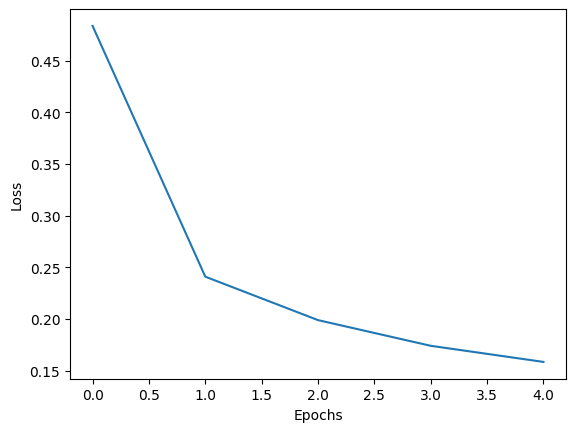

In [ ]:
plt.plot(train_history.history['loss'])
plt.xlabel('Epochs')
plt.ylabel('Loss')

Text(0, 0.5, 'Loss')

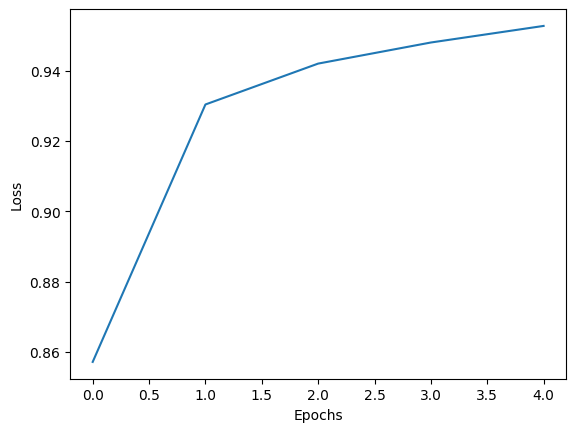

In [ ]:
plt.plot(train_history.history['accuracy'])
plt.xlabel('Epochs')
plt.ylabel('Loss')

In [ ]:
Y_pred = model.predict(X_test_normalized)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [ ]:
Y_pred[1976]

array([5.1849167e-04, 7.2344403e-07, 5.2266441e-05, 9.6980977e-01,
       1.1174229e-10, 2.5637148e-02, 2.3921981e-08, 2.6028557e-04,
       4.3805059e-05, 3.6775912e-03], dtype=float32)

In [ ]:
[float(x) for x in Y_pred[1976]]

[0.0005184916662983596,
 7.234440317915869e-07,
 5.226644134381786e-05,
 0.9698097705841064,
 1.1174228903287897e-10,
 0.025637147948145866,
 2.3921980840668766e-08,
 0.00026028556749224663,
 4.380505924928002e-05,
 0.0036775912158191204]

In [ ]:
np.argmax(Y_pred[1976])

np.int64(3)

In [ ]:
y_pred = np.argmax(Y_pred, axis=-1)

In [ ]:
y_pred[1976]

np.int64(3)

In [ ]:
test_accuracy = np.mean(y_pred == y_test)
print(test_accuracy)

0.9513


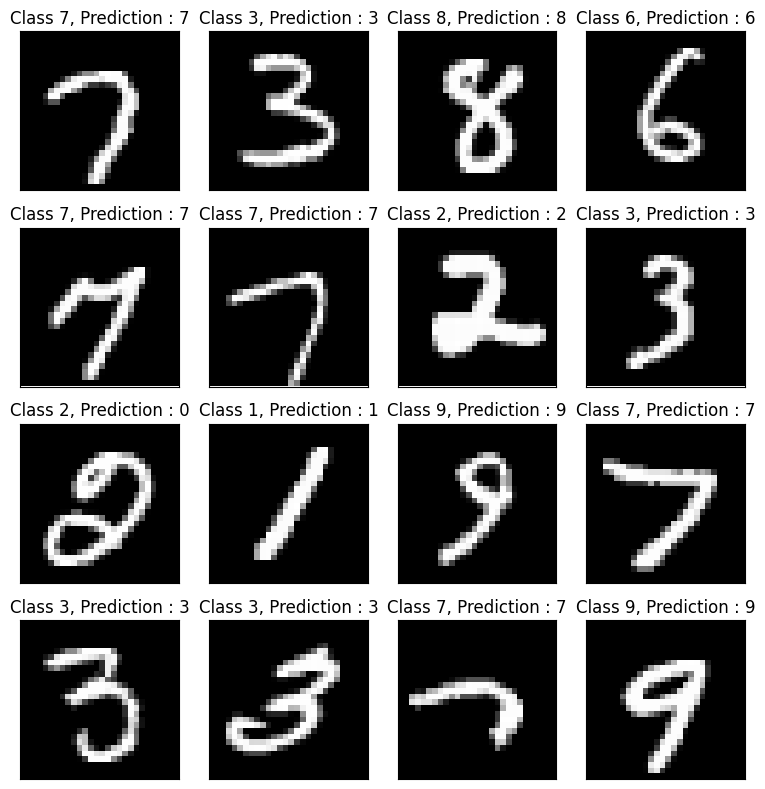

In [ ]:
plt.figure(figsize=(8, 8))
n = 4
for i in range(n * n):
    plt.subplot(n, n, i+1)
    random_idx = np.random.randint(0, X_test.shape[0])
    plt.imshow(X_test[random_idx], cmap='gray')
    plt.title(f'Class {y_test[random_idx]}, Prediction : {y_pred[random_idx]}')
    plt.xticks([])
    plt.yticks([])
    plt.tight_layout()

# Convolutional Neural Network

In [ ]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D

In [ ]:
cnn_model = Sequential([
    Conv2D(16, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    Conv2D(16, (3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(32, (3, 3), activation='relu'),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

cnn_model.summary()

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 10, 10, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 32)       │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 4, 4, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49,850 (194.73 KB)

 Trainable params: 49,850 (194.73 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
cnn_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics = ['accuracy']
)

In [ ]:
cnn_train_history = cnn_model.fit(X_train_normalized, Y_train, batch_size=64, epochs=5)

Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 51s 52ms/step - accuracy: 0.8617 - loss: 0.4617
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 49s 52ms/step - accuracy: 0.9825 - loss: 0.0555
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 82s 52ms/step - accuracy: 0.9886 - loss: 0.0360
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 48s 51ms/step - accuracy: 0.9909 - loss: 0.0282
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 49s 52ms/step - accuracy: 0.9928 - loss: 0.0219


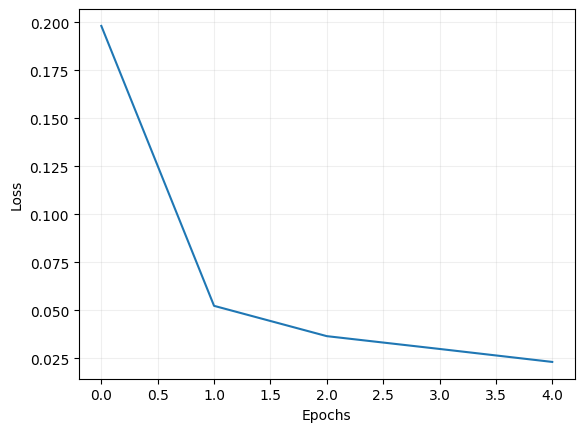

In [ ]:
plt.plot(cnn_train_history.history['loss'])
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(alpha=0.2)
plt.show()

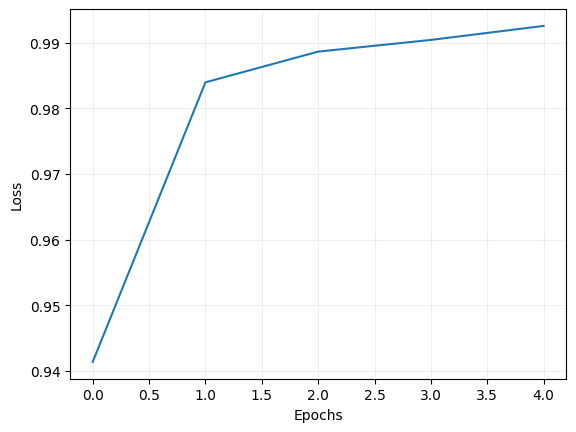

In [ ]:
plt.plot(cnn_train_history.history['accuracy'])
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(alpha=0.2)
plt.show()

In [ ]:
cnn_Y_pred = cnn_model.predict(X_test_normalized)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step


In [ ]:
cnn_y_pred = np.argmax(cnn_Y_pred, axis=-1)

In [ ]:
cnn_test_accuracy = np.mean(cnn_y_pred == y_test)
print(cnn_test_accuracy)

0.9904


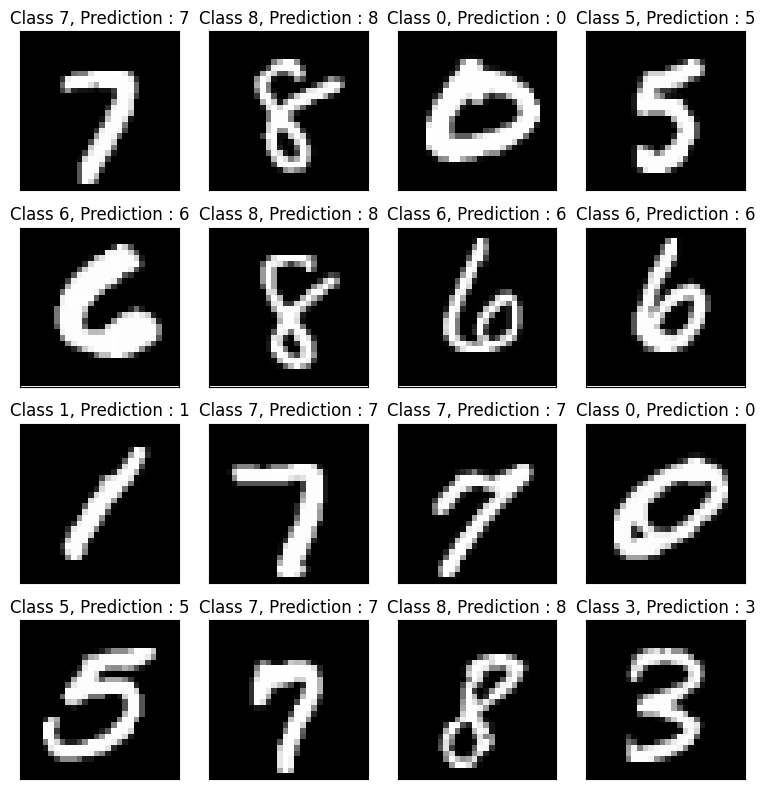

In [ ]:
plt.figure(figsize=(8, 8))
n = 4
for i in range(n * n):
    plt.subplot(n, n, i+1)
    random_idx = np.random.randint(0, X_test.shape[0])
    plt.imshow(X_test[random_idx], cmap='gray')
    plt.title(f'Class {y_test[random_idx]}, Prediction : {cnn_y_pred[random_idx]}')
    plt.xticks([])
    plt.yticks([])
    plt.tight_layout()